# Lab 05 — Sequence Models: RNN, LSTM and GRU

Dataset: IMDb Movie Reviews. Task: binary sentiment classification (`0 = negative`, `1 = positive`).

## Thiết lập

In [1]:
from collections import Counter
from pathlib import Path
import random
import re
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

LAB_DIR = Path.cwd().resolve()
if LAB_DIR.name != 'lab05':
    LAB_DIR = LAB_DIR / 'labs' / 'lab05'
REPO_ROOT = LAB_DIR.parents[1]
DATA_DIR = REPO_ROOT / 'labs' / 'lab04' / 'data'
sys.path.insert(0, str(LAB_DIR))

from rnn_cell import SimpleRNNCell

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, torch.get_num_threads())))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

Device: cpu


## 11. Experiment 1 — Dataset inspection

In [2]:
splits = {
    name: pd.read_csv(DATA_DIR / f'imdb_{name}.csv.gz')
    for name in ['train', 'validation', 'test']
}
dataset = pd.concat(
    [frame.assign(split=name) for name, frame in splits.items()],
    ignore_index=True,
)

TOKEN_PATTERN = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?")
def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())

sequence_lengths = dataset['text'].map(lambda text: len(tokenize(text)))
class_table = (
    dataset['label'].value_counts().sort_index().rename_axis('label').reset_index(name='count')
)
class_table['class'] = class_table['label'].map({0: 'Negative', 1: 'Positive'})
class_table['percentage'] = (class_table['count'] / len(dataset) * 100).round(2)

inspection = pd.Series({
    'samples': len(dataset),
    'classes': dataset['label'].nunique(),
    'minimum_sequence_length': sequence_lengths.min(),
    'median_sequence_length': sequence_lengths.median(),
    'mean_sequence_length': sequence_lengths.mean(),
    'maximum_sequence_length': sequence_lengths.max(),
    'duplicate_documents': dataset['text'].duplicated().sum(),
    'missing_text': dataset['text'].isna().sum() + dataset['text'].fillna('').str.strip().eq('').sum(),
    'missing_labels': dataset['label'].isna().sum(),
})
display(class_table[['class', 'count', 'percentage']])
inspection.to_frame('value').round(2)

,class,count,percentage
0,Negative,24698,49.81
1,Positive,24884,50.19


,value
samples,49582.00
classes,2.00
minimum_sequence_length,6.00
median_sequence_length,175.00
mean_sequence_length,233.95
maximum_sequence_length,2482.00
duplicate_documents,0.00
missing_text,0.00
missing_labels,0.00


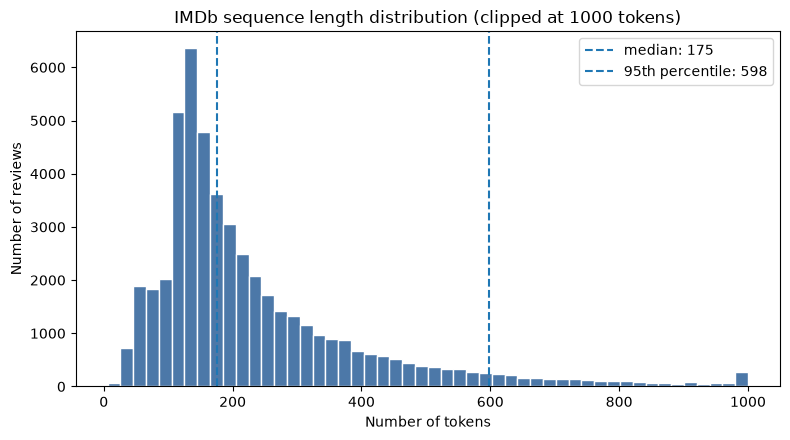

In [3]:
plt.figure(figsize=(8, 4.5))
plt.hist(sequence_lengths.clip(upper=1000), bins=50, color='#4c78a8', edgecolor='white')
for value, label in [(sequence_lengths.median(), 'median'), (sequence_lengths.quantile(0.95), '95th percentile')]:
    plt.axvline(value, linestyle='--', label=f'{label}: {value:.0f}')
plt.title('IMDb sequence length distribution (clipped at 1000 tokens)')
plt.xlabel('Number of tokens')
plt.ylabel('Number of reviews')
plt.legend()
plt.tight_layout()
plt.show()

**Max-length selection:** Dataset có median sequence length khoảng 175 tokens và mean khoảng 234 tokens. Vì vậy max_length = 50 giữ khá ít nội dung của review. Trong thống kê token retention, max_length = 50 giữ 21.28%, max_length = 100 giữ 41.13% và max_length = 200 giữ 68.20% tổng số token.

Do đó max_length nên được chọn dựa trên cả sequence-length distribution, lượng context được giữ lại, performance và computational cost, không chỉ dựa vào tốc độ chạy.

## 12. Tokenization và vocabulary

In [4]:
PAD_TOKEN = '<pad>'
UNK_TOKEN = '<unk>'
VOCAB_SIZE = 15_000

train_tokenized_full = [tokenize(text) for text in splits['train']['text']]
token_counts = Counter(token for document in train_tokenized_full for token in document)
vocabulary = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for token, _ in token_counts.most_common(VOCAB_SIZE - 2):
    vocabulary[token] = len(vocabulary)

print('Vocabulary size:', len(vocabulary))
print('PAD id:', vocabulary[PAD_TOKEN], '| UNK id:', vocabulary[UNK_TOKEN])

Vocabulary size: 15000
PAD id: 0 | UNK id: 1


Padding thêm token `PAD` để các sequence trong batch có cùng chiều dài; padding không phải thông tin ngôn ngữ. Truncation cắt bỏ token khi review dài hơn `max_length`, nên có thể làm mất nội dung thật.

## 13. Experiment 2 — Padding và truncation

In [5]:
total_tokens = int(sequence_lengths.sum())
retention_rows = []
for max_length in [50, 100, 200]:
    retained = int(sequence_lengths.clip(upper=max_length).sum())
    retention_rows.append({
        'max_length': max_length,
        'tokens_retained_percent': round(retained / total_tokens * 100, 2),
    })
retention_table = pd.DataFrame(retention_rows)
retention_table

,max_length,tokens_retained_percent
0,50,21.28
1,100,41.13
2,200,68.20


Kết quả performance và training time cho ba giá trị được báo cáo ở Experiment 5.

## 14. Core implementation — Simple RNN cell

In [6]:
x_t = torch.tensor([[1.0, 0.0]])
h_prev = torch.tensor([[0.5, 0.2]])
manual_cell = SimpleRNNCell(input_size=2, hidden_size=2)

with torch.no_grad():
    manual_cell.W_xh.copy_(torch.tensor([[0.5, 0.2], [0.1, 0.4]]))
    manual_cell.W_hh.copy_(torch.tensor([[0.3, 0.1], [0.2, 0.5]]))
    manual_cell.b_h.zero_()

framework_cell = nn.RNNCell(input_size=2, hidden_size=2, nonlinearity='tanh')
with torch.no_grad():
    framework_cell.weight_ih.copy_(manual_cell.W_xh)
    framework_cell.weight_hh.copy_(manual_cell.W_hh)
    framework_cell.bias_ih.zero_()
    framework_cell.bias_hh.zero_()

manual_output = manual_cell(x_t, h_prev)
framework_output = framework_cell(x_t, h_prev)
print('SimpleRNNCell:', manual_output)
print('torch.nn.RNNCell:', framework_output)
print('Match:', torch.allclose(manual_output, framework_output, atol=1e-6))

SimpleRNNCell: tensor([[0.5850, 0.2913]], grad_fn=<TanhBackward0>)
torch.nn.RNNCell: tensor([[0.5850, 0.2913]], grad_fn=<TanhBackward0>)
Match: True


Kết quả của `SimpleRNNCell` được đối chiếu với `torch.nn.RNNCell`. Phần giải thích chi tiết forward pass được hoàn thiện trong bài tính cá nhân.

## Chuẩn bị tập thí nghiệm

In [7]:
def balanced_sample(frame, samples_per_class, seed):
    sampled = [
        frame[frame['label'] == label].sample(n=samples_per_class, random_state=seed)
        for label in sorted(frame['label'].unique())
    ]
    return pd.concat(sampled).sample(frac=1, random_state=seed).reset_index(drop=True)

experiment_splits = {
    'train': balanced_sample(splits['train'], 2_000, SEED),
    'validation': balanced_sample(splits['validation'], 500, SEED),
    'test': balanced_sample(splits['test'], 1_000, SEED),
}
pd.DataFrame([
    {'split': name, 'samples': len(frame), 'negative': int((frame.label == 0).sum()), 'positive': int((frame.label == 1).sum())}
    for name, frame in experiment_splits.items()
])

,split,samples,negative,positive
0,train,4000,2000,2000
1,validation,1000,500,500
2,test,2000,1000,1000


Các recurrent experiment dùng 4.000 train, 1.000 validation và 2.000 test samples cân bằng, cùng `random_state = 42`. Việc dùng tập con được ghi rõ để kết quả không bị hiểu nhầm là huấn luyện trên toàn bộ corpus.

In [8]:
def encode_frame(frame, max_length):
    ids = np.zeros((len(frame), max_length), dtype=np.int64)
    lengths = np.zeros(len(frame), dtype=np.int64)
    for row, text in enumerate(frame['text']):
        token_ids = [vocabulary.get(token, 1) for token in tokenize(text)][:max_length]
        length = max(1, len(token_ids))
        ids[row, :len(token_ids)] = token_ids
        lengths[row] = length
    labels = frame['label'].to_numpy(dtype=np.float32)
    return torch.from_numpy(ids), torch.from_numpy(lengths), torch.from_numpy(labels)


def make_loaders(max_length, batch_size=128):
    loaders = {}
    generator = torch.Generator().manual_seed(SEED)
    for name, frame in experiment_splits.items():
        tensors = encode_frame(frame, max_length)
        loaders[name] = DataLoader(
            TensorDataset(*tensors),
            batch_size=batch_size,
            shuffle=(name == 'train'),
            generator=generator if name == 'train' else None,
        )
    return loaders


class SequenceClassifier(nn.Module):
    def __init__(self, architecture, vocab_size, embedding_dim=32, hidden_size=32):
        super().__init__()
        self.architecture = architecture
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        recurrent_class = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[architecture]
        self.recurrent = recurrent_class(embedding_dim, hidden_size, batch_first=True)
        self.classifier = nn.Linear(hidden_size, 1)

    def forward(self, token_ids, lengths):
        embedded = self.embedding(token_ids)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, state = self.recurrent(packed)
        hidden = state[0] if self.architecture == 'LSTM' else state
        return self.classifier(hidden[-1]).squeeze(1)


def predict_loader(model, loader):
    model.eval()
    probabilities, labels = [], []
    with torch.no_grad():
        for token_ids, lengths, batch_labels in loader:
            logits = model(token_ids.to(DEVICE), lengths.to(DEVICE))
            probabilities.extend(torch.sigmoid(logits).cpu().numpy())
            labels.extend(batch_labels.numpy())
    probabilities = np.asarray(probabilities)
    return np.asarray(labels, dtype=int), probabilities, (probabilities >= 0.5).astype(int)


def evaluate_predictions(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
    }


def train_sequence_model(architecture, max_length, epochs=8):
    torch.manual_seed(SEED)
    loaders = make_loaders(max_length)
    model = SequenceClassifier(architecture, len(vocabulary)).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
    criterion = nn.BCEWithLogitsLoss()
    history = []
    start = perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        train_loss_sum = 0.0
        for token_ids, lengths, labels in loaders['train']:
            optimizer.zero_grad()
            logits = model(token_ids.to(DEVICE), lengths.to(DEVICE))
            loss = criterion(logits, labels.to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_loss_sum += loss.item() * len(labels)

        model.eval()
        validation_loss_sum = 0.0
        with torch.no_grad():
            for token_ids, lengths, labels in loaders['validation']:
                logits = model(token_ids.to(DEVICE), lengths.to(DEVICE))
                loss = criterion(logits, labels.to(DEVICE))
                validation_loss_sum += loss.item() * len(labels)
        history.append({
            'epoch': epoch,
            'train_loss': train_loss_sum / len(loaders['train'].dataset),
            'validation_loss': validation_loss_sum / len(loaders['validation'].dataset),
        })
    training_time = perf_counter() - start
    y_validation, validation_prob, validation_pred = predict_loader(model, loaders['validation'])
    y_test, test_prob, test_pred = predict_loader(model, loaders['test'])
    return {
        'model': model,
        'loaders': loaders,
        'history': pd.DataFrame(history),
        'training_time': training_time,
        'parameters': sum(parameter.numel() for parameter in model.parameters()),
        'validation_metrics': evaluate_predictions(y_validation, validation_pred),
        'test_metrics': evaluate_predictions(y_test, test_pred),
        'test_labels': y_test,
        'test_probabilities': test_prob,
        'test_predictions': test_pred,
    }

## 15. Experiment 3 — Baseline

In [9]:
baseline_start = perf_counter()
tfidf = TfidfVectorizer(max_features=15_000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(experiment_splits['train']['text'])
X_validation = tfidf.transform(experiment_splits['validation']['text'])
X_test = tfidf.transform(experiment_splits['test']['text'])
baseline_model = LogisticRegression(max_iter=1000, solver='liblinear', random_state=SEED)
baseline_model.fit(X_train, experiment_splits['train']['label'])
baseline_time = perf_counter() - baseline_start
baseline_validation_pred = baseline_model.predict(X_validation)
baseline_test_pred = baseline_model.predict(X_test)
baseline_validation_metrics = evaluate_predictions(experiment_splits['validation']['label'], baseline_validation_pred)
baseline_test_metrics = evaluate_predictions(experiment_splits['test']['label'], baseline_test_pred)
pd.DataFrame([{'split': 'validation', **baseline_validation_metrics}, {'split': 'test', **baseline_test_metrics}])

,split,accuracy,precision,recall,f1
0,validation,0.874,0.852830,0.904,0.877670
1,test,0.870,0.860624,0.883,0.871668


**Nhận xét:** Trên tập con Lab 05, TF-IDF + Logistic Regression đạt test F1 = 0.8717, cao hơn các recurrent model trong cấu hình thí nghiệm hiện tại. Lab 04 gốc đạt test F1 = 0.907229 trên toàn bộ split (9.917 mẫu test); đây là mốc tham chiếu, không phải kết quả đo trên cùng tập con.

Điều này không có nghĩa RNN không sử dụng sequence. Về cơ chế, RNN xử lý token theo thứ tự thông qua hidden state, còn TF-IDF không mô hình hóa sequence trực tiếp. Tuy nhiên, kết quả này cho thấy sequence modeling không đảm bảo classification performance sẽ cao hơn TF-IDF trên mọi cấu hình hoặc dataset.

**Bằng chứng từ experiment:** Ở Experiment 6, khi từ `excellent` nằm gần đầu, giữa và cuối các câu thử, GRU cho P(positive) lần lượt là 0.8340, 0.4107 và 0.1090; prediction chuyển từ Positive sang Negative. Output này cho thấy model phản ứng khác nhau theo vị trí và context của từ sentiment. Tuy nhiên các câu thử không giống hệt nhau ngoài vị trí của từ, nên chưa thể kết luận riêng word order gây ra thay đổi này. Kết quả F1 ở trên cũng không chứng minh RNN luôn phân loại tốt hơn TF-IDF.

## 16–18. LSTM và GRU

RNN, LSTM và GRU đều duy trì state theo sequence. LSTM có cell state riêng cùng forget/input/output gates; GRU dùng cơ chế update/reset và không có cell state riêng. Phần giải thích gate chi tiết thuộc bài tính cá nhân.

## 19. Experiment 4 — RNN vs LSTM vs GRU

In [10]:
architecture_runs = {}
for architecture in ['RNN', 'LSTM', 'GRU']:
    print('Training', architecture)
    architecture_runs[architecture] = train_sequence_model(architecture, max_length=100, epochs=8)

architecture_rows = []
for architecture, run in architecture_runs.items():
    architecture_rows.append({
        'model': architecture,
        'parameters': run['parameters'],
        'training_time_sec': round(run['training_time'], 3),
        'epochs': 8,
        'max_length': 100,
        **{key: round(value, 6) for key, value in run['test_metrics'].items()},
    })
architecture_table = pd.DataFrame(architecture_rows)
architecture_table

Training RNN


Training LSTM


Training GRU


,model,parameters,training_time_sec,epochs,max_length,accuracy,precision,recall,f1
0,RNN,482145,3.979,8,100,0.5920,0.591089,0.597,0.594030
1,LSTM,488481,12.844,8,100,0.6580,0.663561,0.641,0.652085
2,GRU,486369,10.185,8,100,0.6775,0.720497,0.580,0.642659


**Nhận xét:** Trong ba recurrent model, RNN có F1 thấp nhất là 0.5940. LSTM có F1 cao nhất là 0.6521, trong khi GRU có accuracy cao nhất là 0.6775 và precision cao nhất là 0.7205 nhưng recall chỉ là 0.5800.

Vì vậy không có một model tốt nhất theo tất cả metric. Nếu ưu tiên F1 thì LSTM tốt nhất trong thí nghiệm này. Kết quả cũng phù hợp một phần với prediction rằng LSTM có thể xử lý dependency dài tốt hơn Simple RNN, nhưng experiment này chưa đủ để khẳng định nguyên nhân chỉ đến từ long-range dependency.

## 20. Experiment 5 — Sequence length

In [11]:
length_runs = {100: architecture_runs['GRU']}
for max_length in [50, 200]:
    print('Training GRU with max_length =', max_length)
    length_runs[max_length] = train_sequence_model('GRU', max_length=max_length, epochs=8)

length_rows = []
retention_lookup = retention_table.set_index('max_length')['tokens_retained_percent'].to_dict()
for max_length in [50, 100, 200]:
    run = length_runs[max_length]
    length_rows.append({
        'max_length': max_length,
        'tokens_retained_percent': retention_lookup[max_length],
        'training_time_sec': round(run['training_time'], 3),
        'validation_loss': round(run['history'].iloc[-1]['validation_loss'], 6),
        'test_accuracy': round(run['test_metrics']['accuracy'], 6),
        'test_f1': round(run['test_metrics']['f1'], 6),
    })
length_table = pd.DataFrame(length_rows)
length_table

Training GRU with max_length = 50


Training GRU with max_length = 200


,max_length,tokens_retained_percent,training_time_sec,validation_loss,test_accuracy,test_f1
0,50,21.28,4.442,0.870881,0.6450,0.650934
1,100,41.13,10.185,0.835067,0.6775,0.642659
2,200,68.20,34.310,0.679584,0.7160,0.725869


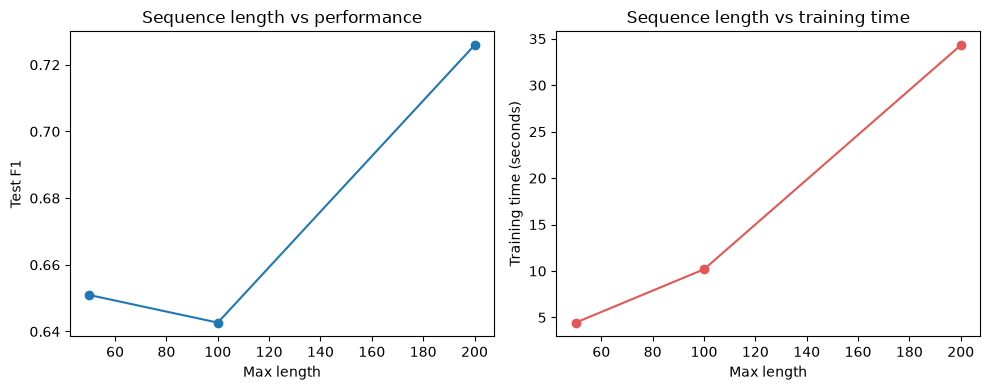

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(length_table['max_length'], length_table['test_f1'], marker='o')
axes[0].set(xlabel='Max length', ylabel='Test F1', title='Sequence length vs performance')
axes[1].plot(length_table['max_length'], length_table['training_time_sec'], marker='o', color='#e45756')
axes[1].set(xlabel='Max length', ylabel='Training time (seconds)', title='Sequence length vs training time')
plt.tight_layout()
plt.show()

**Nhận xét:** Tăng max_length không luôn làm performance tăng. Khi tăng từ 50 lên 100, test F1 giảm nhẹ từ 0.6509 xuống 0.6427. Khi tăng lên 200, test F1 tăng lên 0.7259.

Lượng token được giữ tăng từ 21.28% ở max_length = 50 lên 68.20% ở max_length = 200. Tuy nhiên training time cũng tăng từ 6.99 giây lên 57.53 giây.

Kết quả cho thấy có trade-off giữa lượng context được giữ lại và computational cost.

## 21. Experiment 6 — Long-range dependency

In [13]:
best_architecture = max(architecture_runs, key=lambda name: architecture_runs[name]['validation_metrics']['f1'])
best_run = architecture_runs[best_architecture]
best_model = best_run['model']

position_examples = pd.DataFrame({
    'position': ['beginning', 'beginning', 'middle', 'middle', 'end', 'end'],
    'text': [
        'Excellent movie, although several scenes in the middle were unnecessarily slow.',
        'Terrible movie, although several scenes in the middle were visually impressive.',
        'The movie was slow at first but excellent and then continued with several ordinary scenes.',
        'The movie looked promising at first but terrible and then continued with several ordinary scenes.',
        'The movie was, despite many unnecessary scenes, ultimately excellent.',
        'The movie was, despite many unnecessary scenes, ultimately terrible.',
    ],
})
position_ids, position_lengths, _ = encode_frame(position_examples.assign(label=0), 100)
best_model.eval()
with torch.no_grad():
    position_probabilities = torch.sigmoid(
        best_model(position_ids.to(DEVICE), position_lengths.to(DEVICE))
    ).cpu().numpy()
position_examples['positive_probability'] = position_probabilities.round(4)
position_examples['prediction'] = np.where(position_probabilities >= 0.5, 'Positive', 'Negative')
position_examples

,position,text,positive_probability,prediction
0,beginning,"Excellent movie, although several scenes in th...",0.8340,Positive
1,beginning,"Terrible movie, although several scenes in the...",0.1180,Negative
2,middle,The movie was slow at first but excellent and ...,0.4107,Negative
3,middle,The movie looked promising at first but terrib...,0.0339,Negative
4,end,"The movie was, despite many unnecessary scenes...",0.1090,Negative
5,end,"The movie was, despite many unnecessary scenes...",0.0874,Negative


**Nhận xét:** Trong các ví dụ nhỏ này, prediction thay đổi theo vị trí và context của từ sentiment. Model dự đoán đúng khi `Excellent` hoặc `Terrible` xuất hiện gần đầu câu, nhưng trường hợp `excellent` ở giữa hoặc cuối câu vẫn bị dự đoán Negative.

Đây chỉ là empirical observation cho thấy vị trí và context có thể ảnh hưởng đến prediction. Experiment nhỏ này không đủ để chứng minh vanishing gradient hoặc xác định một nguyên nhân duy nhất cho lỗi.

## 22. Evaluation

In [14]:
lab04_reference = pd.read_csv(REPO_ROOT / 'labs' / 'lab04' / 'results.csv')
lab04_reference = lab04_reference.loc[
    (lab04_reference['model'] == 'Logistic Regression')
    & (lab04_reference['representation'] == 'TF-IDF unigram + bigram')
    & (lab04_reference['split'] == 'test')
].iloc[0]
full_split_sizes = {f'{name}_samples': len(frame) for name, frame in splits.items()}
subset_split_sizes = {f'{name}_samples': len(frame) for name, frame in experiment_splits.items()}
result_rows = [{
    'experiment': 'lab04_reference',
    'model': 'Logistic Regression',
    'representation': 'TF-IDF unigram + bigram',
    'parameters': np.nan,
    'training_time_sec': lab04_reference['training_time_sec'],
    'epochs': np.nan,
    'max_length': np.nan,
    'vocabulary_size': int(lab04_reference['vocabulary_size']),
    **full_split_sizes,
    **{key: lab04_reference[key] for key in ['accuracy', 'precision', 'recall', 'f1']},
}, {
    'experiment': 'baseline_subset',
    'model': 'Logistic Regression',
    'representation': 'TF-IDF unigram + bigram',
    'parameters': len(tfidf.vocabulary_) + 1,
    'training_time_sec': round(baseline_time, 3),
    'epochs': 1,
    'max_length': np.nan,
    'vocabulary_size': len(tfidf.vocabulary_),
    **subset_split_sizes,
    **{key: round(value, 6) for key, value in baseline_test_metrics.items()},
}]

for architecture, run in architecture_runs.items():
    result_rows.append({
        'experiment': 'architecture',
        'model': architecture,
        'representation': 'Embedding',
        'parameters': run['parameters'],
        'training_time_sec': round(run['training_time'], 3),
        'epochs': 8,
        'max_length': 100,
        'vocabulary_size': len(vocabulary),
        **subset_split_sizes,
        **{key: round(value, 6) for key, value in run['test_metrics'].items()},
    })

for max_length in [50, 100, 200]:
    run = length_runs[max_length]
    result_rows.append({
        'experiment': 'sequence_length',
        'model': 'GRU',
        'representation': 'Embedding',
        'parameters': run['parameters'],
        'training_time_sec': round(run['training_time'], 3),
        'epochs': 8,
        'max_length': max_length,
        'vocabulary_size': len(vocabulary),
        **subset_split_sizes,
        **{key: round(value, 6) for key, value in run['test_metrics'].items()},
    })

results_df = pd.DataFrame(result_rows)
results_df.to_csv(LAB_DIR / 'results.csv', index=False)
results_df

,experiment,model,representation,parameters,training_time_sec,epochs,max_length,vocabulary_size,train_samples,validation_samples,test_samples,accuracy,precision,recall,f1
0,lab04_reference,Logistic Regression,TF-IDF unigram + bigram,NaN,24.169,NaN,NaN,100000,29749,9916,9917,0.905919,0.898031,0.916616,0.907229
1,baseline_subset,Logistic Regression,TF-IDF unigram + bigram,15001.0,2.295,1.0,NaN,15000,4000,1000,2000,0.870000,0.860624,0.883000,0.871668
2,architecture,RNN,Embedding,482145.0,3.979,8.0,100.0,15000,4000,1000,2000,0.592000,0.591089,0.597000,0.594030
3,architecture,LSTM,Embedding,488481.0,12.844,8.0,100.0,15000,4000,1000,2000,0.658000,0.663561,0.641000,0.652085
4,architecture,GRU,Embedding,486369.0,10.185,8.0,100.0,15000,4000,1000,2000,0.677500,0.720497,0.580000,0.642659
5,sequence_length,GRU,Embedding,486369.0,4.442,8.0,50.0,15000,4000,1000,2000,0.645000,0.640232,0.662000,0.650934
6,sequence_length,GRU,Embedding,486369.0,10.185,8.0,100.0,15000,4000,1000,2000,0.677500,0.720497,0.580000,0.642659
7,sequence_length,GRU,Embedding,486369.0,34.310,8.0,200.0,15000,4000,1000,2000,0.716000,0.701493,0.752000,0.725869


## 23. Learning curves

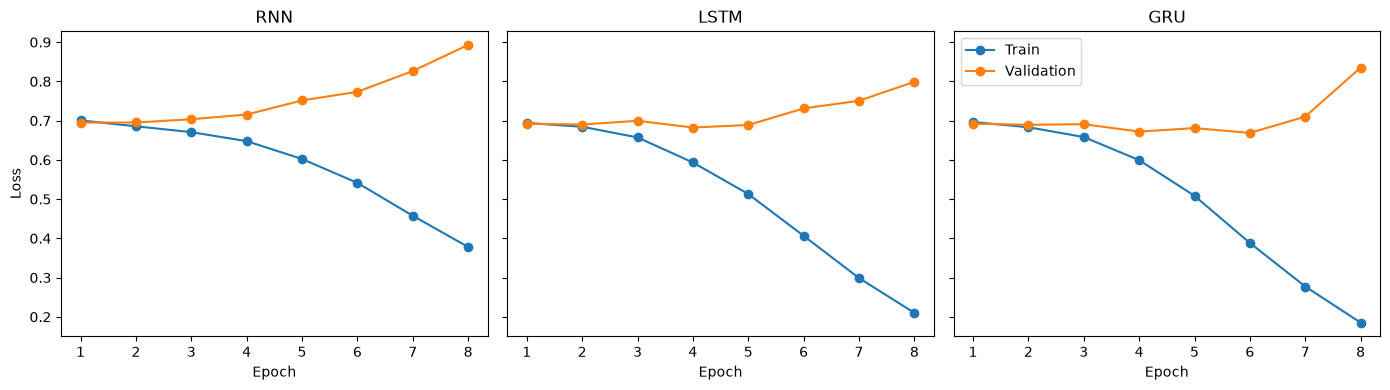

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for axis, architecture in zip(axes, ['RNN', 'LSTM', 'GRU']):
    history = architecture_runs[architecture]['history']
    axis.plot(history['epoch'], history['train_loss'], marker='o', label='Train')
    axis.plot(history['epoch'], history['validation_loss'], marker='o', label='Validation')
    axis.set_title(architecture)
    axis.set_xlabel('Epoch')
    axis.set_xticks(history['epoch'])
axes[0].set_ylabel('Loss')
axes[-1].legend()
plt.tight_layout()
plt.savefig(LAB_DIR / 'learning_curves.png', dpi=160, bbox_inches='tight')
plt.show()

**Nhận xét:** Cả RNN, LSTM và GRU đều có dấu hiệu overfitting.

Với RNN, training loss giảm liên tục qua các epoch nhưng validation loss bắt đầu tăng dần sau các epoch đầu và tăng rõ ở những epoch cuối.

LSTM cũng có xu hướng tương tự: training loss tiếp tục giảm mạnh trong khi validation loss chỉ giảm nhẹ lúc đầu rồi tăng trở lại từ khoảng giữa quá trình training.

GRU có training loss giảm mạnh nhất, nhưng validation loss tăng rõ ở các epoch cuối, đặc biệt từ khoảng epoch 7 đến epoch 8.

Như vậy, model tiếp tục fit training data tốt hơn nhưng performance trên validation không cải thiện tương ứng. Đây là dấu hiệu overfitting.

## Confusion matrix

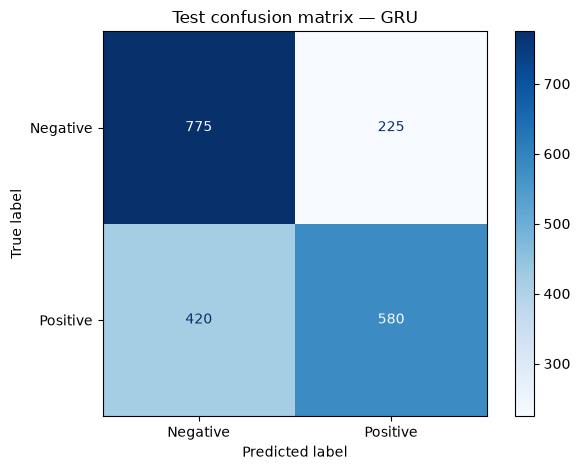

Selected by validation F1: GRU
[[775 225]
 [420 580]]


In [16]:
best_confusion = confusion_matrix(best_run['test_labels'], best_run['test_predictions'])
display_cm = ConfusionMatrixDisplay(best_confusion, display_labels=['Negative', 'Positive'])
display_cm.plot(cmap='Blues', values_format='d')
display_cm.ax_.set_title(f'Test confusion matrix — {best_architecture}')
plt.tight_layout()
plt.savefig(LAB_DIR / 'confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()
print('Selected by validation F1:', best_architecture)
print(best_confusion)

**Nhận xét:** Confusion matrix của GRU trên test set là TN = 775, FP = 225, FN = 420 và TP = 580.

False negative nhiều hơn false positive, nghĩa là model bỏ sót nhiều review positive hơn số review negative bị dự đoán thành positive. Điều này phù hợp với precision = 0.7205 cao hơn recall = 0.5800.

## 24. Error analysis

In [17]:
analysis_frame = experiment_splits['test'].copy()
analysis_frame['prediction'] = best_run['test_predictions']
analysis_frame['probability'] = best_run['test_probabilities']
analysis_frame['correct'] = analysis_frame['label'] == analysis_frame['prediction']
analysis_frame['sequence_length'] = analysis_frame['text'].map(lambda text: len(tokenize(text)))
analysis_frame['truncated'] = analysis_frame['sequence_length'] > 100
analysis_frame['text_preview'] = analysis_frame['text'].str.replace(r'\s+', ' ', regex=True).str.slice(0, 500)

correct_examples = analysis_frame[analysis_frame['correct']].groupby('label', group_keys=False).head(2).head(3)
incorrect_examples = analysis_frame[~analysis_frame['correct']].groupby('label', group_keys=False).head(2).head(3)
error_examples = pd.concat([correct_examples, incorrect_examples])
error_examples[['text_preview', 'label', 'prediction', 'probability', 'sequence_length', 'truncated', 'correct']]

,text_preview,label,prediction,probability,sequence_length,truncated,correct
1,I am definitely in the minority opinion on thi...,0,0,0.016931,159,True,True
2,Great movie. I was laughing all time through. ...,1,1,0.504335,84,False,True
3,"Oh, my. Oh, this is a *really* bad movie. The ...",0,0,0.016416,273,True,True
0,"I did not intend to write this review, but hav...",1,0,0.022587,565,True,False
5,"This movie had an interesting cast, it mat not...",1,0,0.047002,157,True,False
14,"I watched this film in youth group, where my o...",0,1,0.855975,787,True,False


Các ví dụ và dữ kiện được xuất tự động; nguyên nhân từng lỗi được hoàn thiện trong `error_analysis.md` sau khi tự đọc toàn bộ review.

## 25. So sánh với Lab 04

| Property | TF-IDF + LR | Avg Word2Vec + LR | RNN | LSTM | GRU |
|---|---:|---:|---:|---:|---:|
| Sparse representation | ✓ |  |  |  |  |
| Dense representation |  | ✓ | ✓ | ✓ | ✓ |
| Word order | Limited | ✗ | ✓ | ✓ | ✓ |
| Context-dependent state | ✗ | ✗ | ✓ | ✓ | ✓ |
| Long dependency | ✗ | ✗ | Limited | Improved | Improved |
| Computational cost | Low | Low | Higher | Higher | Higher |

**RNN/LSTM/GRU giải quyết được vấn đề gì mà Average Word2Vec không giải quyết tốt?**

Average Word2Vec lấy trung bình các word vectors nên làm mất thứ tự từ và không có state thay đổi theo context. RNN, LSTM và GRU đọc token theo sequence và cập nhật hidden state sau mỗi timestep, nên có thể sử dụng word order và thông tin từ các token trước đó.

**RNN/LSTM/GRU vẫn còn vấn đề gì?**

Các recurrent model vẫn phải xử lý sequence tuần tự nên computational cost tăng khi sequence dài. Simple RNN còn gặp khó với long-range dependency. LSTM và GRU cải thiện vấn đề này bằng các gate nhưng vẫn không loại bỏ hoàn toàn giới hạn của recurrent processing. Ngoài ra, nếu review bị truncation thì context quan trọng vẫn có thể bị mất trước khi đưa vào model.

## 26. Application — Sentiment classifier

In [18]:
application_reviews = pd.DataFrame({
    'type': ['short', 'long', 'negation', 'contrast'],
    'text': [
        'I really enjoyed this movie.',
        'The film begins slowly and spends a long time introducing every character, but the performances become stronger and the final scenes are moving, thoughtful, and memorable.',
        'This movie is not good and I would not recommend it.',
        'I thought the movie would be terrible, but it was surprisingly good.',
    ],
})
application_ids, application_lengths, _ = encode_frame(application_reviews.assign(label=0), 100)
best_model.eval()
with torch.no_grad():
    application_probabilities = torch.sigmoid(
        best_model(application_ids.to(DEVICE), application_lengths.to(DEVICE))
    ).cpu().numpy()
application_reviews['positive_probability'] = application_probabilities.round(4)
application_reviews['prediction'] = np.where(application_probabilities >= 0.5, 'Positive', 'Negative')
application_reviews

,type,text,positive_probability,prediction
0,short,I really enjoyed this movie.,0.7755,Positive
1,long,The film begins slowly and spends a long time ...,0.1812,Negative
2,negation,This movie is not good and I would not recomme...,0.1611,Negative
3,contrast,"I thought the movie would be terrible, but it ...",0.2069,Negative


**Nhận xét:** Model dự đoán đúng review ngắn positive và review có negation negative. Tuy nhiên review dài có sentiment positive ở phần sau lại bị dự đoán Negative, và câu contrast `terrible, but it was surprisingly good` cũng bị dự đoán Negative.

Các kết quả này cho thấy model có thể xử lý một số tín hiệu sentiment đơn giản nhưng vẫn gặp khó với context dài và contrast trong các ví dụ thử nghiệm này. Không thể kết luận nguyên nhân chỉ do một yếu tố nếu chưa phân tích thêm.